<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS06/JS06_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [10]:
!unzip images.zip

Archive:  images.zip
   creating: images/
  inflating: __MACOSX/._images       
   creating: images/test/
  inflating: __MACOSX/images/._test  
   creating: images/training/
  inflating: __MACOSX/images/._training  
   creating: images/test/day/
  inflating: __MACOSX/images/test/._day  
   creating: images/test/night/
  inflating: __MACOSX/images/test/._night  
   creating: images/training/day/
  inflating: __MACOSX/images/training/._day  
   creating: images/training/night/
  inflating: __MACOSX/images/training/._night  
  inflating: images/test/day/20151102_122322.jpg  
  inflating: __MACOSX/images/test/day/._20151102_122322.jpg  
  inflating: images/test/day/20151101_235039.jpg  
  inflating: __MACOSX/images/test/day/._20151101_235039.jpg  
  inflating: images/test/day/20151102_114041.jpg  
  inflating: __MACOSX/images/test/day/._20151102_114041.jpg  
  inflating: images/test/day/20151102_074010.jpg  
  inflating: __MACOSX/images/test/day/._20151102_074010.jpg  
  inflating: images/

In [12]:
train_dir = "images/training/"
test_dir = "images/test/"

In [13]:
from pathlib import Path
import matplotlib.image as mpimg

def load_dataset(img_dir):
  p = Path(img_dir)
  img_list = []
  for d in p.glob('*'):
    label = d.name
    for file in d.glob('*.jpg'):
      img = mpimg.imread(file)
      if img is not None:
        img_list.append((img, label))
  return img_list

train_img = load_dataset("images/training/")
print(len(train_img))

240


In [14]:
train_img = load_dataset(train_dir)

In [15]:
train_img[0]

(array([[[189, 196, 206],
         [161, 168, 178],
         [163, 170, 180],
         ...,
         [172, 187, 194],
         [172, 187, 194],
         [172, 187, 194]],
 
        [[188, 195, 205],
         [161, 168, 178],
         [163, 170, 180],
         ...,
         [172, 187, 194],
         [172, 187, 194],
         [172, 187, 194]],
 
        [[187, 194, 204],
         [160, 167, 177],
         [164, 171, 181],
         ...,
         [172, 187, 194],
         [172, 187, 194],
         [172, 187, 194]],
 
        ...,
 
        [[ 46,  42,  39],
         [ 31,  27,  24],
         [ 29,  25,  22],
         ...,
         [ 37,  29,  26],
         [ 37,  32,  28],
         [ 39,  34,  30]],
 
        [[ 50,  46,  43],
         [ 34,  30,  27],
         [ 30,  26,  23],
         ...,
         [ 35,  27,  24],
         [ 35,  30,  26],
         [ 36,  31,  27]],
 
        [[ 52,  48,  45],
         [ 36,  32,  29],
         [ 31,  27,  24],
         ...,
         [ 32,  24,  21],
  

In [16]:
pick_random = np.random.randint(0, len(train_img))

print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 139
(372, 640, 3)


In [19]:
def random_img_viz(img_list):
  rand_num = np.random.randint(0, len(img_list))

  img = img_list[rand_num][0]
  label = img_list[rand_num][1]
  label_str = 'day' if label == 1 else 'night'

  plt.imshow(img)
  print(f'Shape\t: {img.shape}')
  print(f'Label\t: {label}')

Shape	: (700, 1280, 3)
Label	: day


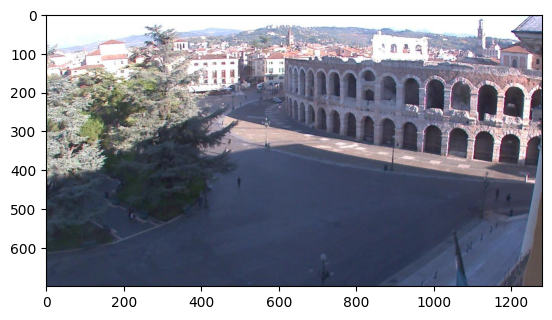

In [20]:
random_img_viz(train_img)

In [21]:
def standarized_input(image):
  std_img = cv2.resize(image, (1100,600))
  return std_img

In [22]:
def label_encoder(label):
  num_val = 0
  if(label == 'day'):
    num_val = 1

  return num_val

In [23]:
def preprocess(img_list):
  std_img_list = []

  for item in img_list:
    image = item[0]
    label = item[1]

    std_img = standarized_input(image)
    img_label = label_encoder(label)
    std_img_list.append((std_img, img_label))

  return std_img_list

In [24]:
train_std_img_list = preprocess(train_img)

In [28]:
pick_random = np.random.randint(0, len(train_std_img_list))

print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 148
(600, 1100, 3)


In [29]:
def avg_brightness(image):
  img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

  sum_brightness = np.sum(img_hsv[:, :, 2])
  area = image.shape[0] * image.shape[1]
  avg = sum_brightness / area

  return avg

Image 151
Avg Brighness: 99.8196


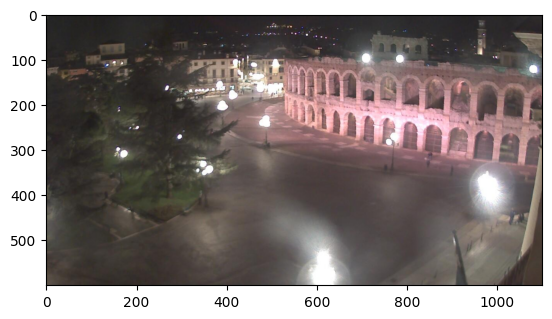

In [30]:
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

In [31]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0

    if avg > threshold:
        pred = 1

    return pred

Image 167
Actual label: 0
Predicted label: 0


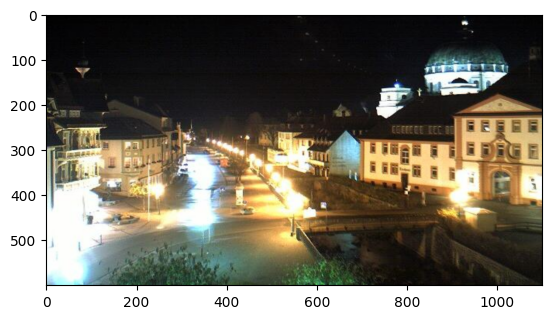

In [32]:
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

In [33]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [35]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [36]:
test_img = load_dataset(test_dir)

test_std_img_list = preprocess(test_img)

evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [37]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [38]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,106.808485,1.0
1,115.034714,1.0
2,126.716241,1.0
3,139.786038,1.0
4,132.133823,1.0


In [39]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,157.660683,1.0
1,105.513033,1.0
2,130.929544,1.0
3,157.826662,1.0
4,98.978082,1.0


In [40]:
from sklearn.svm import SVC

X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [41]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)
y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
